# Préparation des offres d'emploi France Travail

Ce notebook transforme les offres d'emploi collectées sur l'API France Travail en une base propre, prête pour l'analyse et l'extraction des compétences.

**Contexte.** Le TER étudie les compétences demandées dans les offres d'emploi Data / IA (Data Analyst, Data Scientist, Data Engineer, ML Engineer, développeur IA). Les offres ont été collectées le 31/10/2026 par `collect_offres.py` (CDI, CDD et alternance, créées depuis un an au plus).

**Ce que fait le notebook :**

1. charger les offres et décrire leur structure ;
2. repérer les valeurs manquantes ;
3. appliquer les règles de nettoyage, une étape à la fois ;
4. présenter la base obtenue et ses limites.

Les règles sont définies dans `data/processed/dictionnaire_donnees.md`. Le code de chaque étape se trouve dans `nettoyage.py` : le notebook l'appelle et affiche ce qui change.

**Pour l'exécuter**, il faut le JSON de la collecte dans `data/raw/` et les trois tables INSEE dans `data/raw/insee/` (voir le README du dossier).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Le notebook peut être lancé depuis la racine du dépôt ou depuis son dossier.
racine = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "france_travail").exists())
sys.path.insert(0, str(racine / "src" / "france_travail"))
import nettoyage as n

pd.set_option("display.max_colwidth", 80)

## 1. Charger les offres

Le fichier de la collecte est un JSON : chaque offre y est un objet avec des champs imbriqués (par exemple `lieuTravail.commune`). La fonction `charger` le convertit en tableau, avec une ligne par offre et une colonne par variable du dictionnaire. Seules ces colonnes sont gardées.

Tout est d'abord lu comme du texte, pour ne pas perdre les zéros au début des codes (par exemple la commune `01001`).

In [2]:
offres = n.charger(n.FICHIER_ENTREE)
print(f"{len(offres)} offres, {offres.shape[1]} variables")
offres[["job_id", "titre", "code_rome", "type_contrat", "experience", "commune"]].head()

615 offres, 18 variables


,job_id,titre,code_rome,type_contrat,experience,commune
0,215TYNB,"Data Analyst Senior / Analytics Engineer / Python, SQL, Power BI (H/F)",M1419,CDI,exigée,NaN
1,215PDJS,DATA ANALYST - TEMPS PLEIN H/F,M1801,CDI,débutant,10268
2,215NGRL,Data Analyst confirmé (H/F),M1419,CDI,exigée,59350
3,215NGJY,Data analyst (H/F),M1419,CDI,exigée,31555
4,215MPSB,DATA ANALYST - TEMPS PLEIN H/F,M1801,CDI,débutant,51535


La fonction `typer` donne ensuite leur vrai type aux dates (en temps universel, UTC) et à la variable `alternance` (vrai / faux).

In [3]:
offres = n.typer(offres)
offres.dtypes.rename("type").to_frame()

,type
job_id,str
date_creation,"datetime64[us, UTC]"
titre,str
description,str
code_rome,str
intitule_rome,str
entreprise,str
commune,str
lieu_libelle,str
type_contrat,str


**Les variables principales**

| variable | signification |
|---|---|
| `job_id` | identifiant de l'offre chez France Travail |
| `titre`, `description` | intitulé et texte complet de l'offre ; la description sert à l'extraction des compétences |
| `code_rome`, `intitule_rome` | métier selon le répertoire ROME de France Travail |
| `type_contrat`, `alternance` | type de contrat ; l'alternance est indiquée à part dans l'API |
| `experience` | expérience demandée : débutant accepté ou exigée |
| `formation`, `competences` | listes fournies par France Travail, gardées en texte JSON |
| `date_creation`, `date_actualisation` | dates de publication et de dernière mise à jour |
| `date_collecte`, `source` | métadonnées de la collecte, pour la traçabilité |

Ce projet ne cherche pas à prédire une variable : il n'y a donc pas de variable cible. L'objet d'étude est le texte des offres et les compétences qu'il contient.

## 2. Valeurs manquantes

Avant tout nettoyage, on mesure la part d'offres sans valeur pour chaque variable. Pour `formation` et `competences`, une liste vide compte comme une valeur manquante.

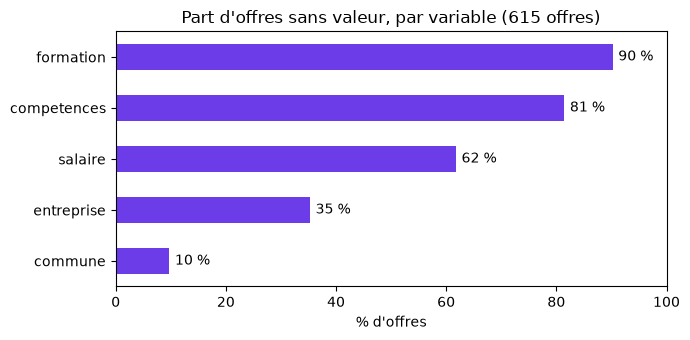

In [4]:
manquantes = offres.isna().mean() * 100
for col in ["formation", "competences"]:
    manquantes[col] = (offres[col] == "[]").mean() * 100
manquantes = manquantes[manquantes > 0].sort_values()

ax = manquantes.plot.barh(figsize=(7, 3.5), color="#6C3CE9")
ax.set_title(f"Part d'offres sans valeur, par variable ({len(offres)} offres)")
ax.set_xlabel("% d'offres")
ax.set_xlim(0, 100)
for i, v in enumerate(manquantes):
    ax.text(v + 1, i, f"{v:.0f} %", va="center")
plt.tight_layout()
plt.show()

**Ce que montre le graphique**

- **Formations et compétences** sont presque toujours vides : France Travail ne les renseigne que pour une minorité d'offres. Pour connaître les compétences demandées, il faudra donc les extraire du texte des descriptions (phase 4 du projet).
- **Le salaire** manque dans la majorité des offres, et **l'entreprise** dans environ un tiers (offres anonymes). Ces variables resteront peu exploitables.
- **La commune** manque pour environ une offre sur dix. On verra à l'étape géographie qu'une partie peut être retrouvée autrement.
- Les variables obligatoires (identifiant, titre, description, dates, contrat) sont toujours présentes.

On ne remplace jamais une valeur manquante par une valeur inventée : une case vide reste vide.

## 3. Nettoyage, étape par étape

Le principe retenu :

- **retirer** une offre seulement quand elle est inutilisable ou hors du périmètre du projet ;
- **signaler** dans une colonne quand il y a un doute, sans supprimer ;
- **tracer** chaque retrait, avec son motif, dans `offres_retirees.csv`.

La liste `retirees` garde les offres retirées à chaque étape.

In [5]:
retirees = []
suivi = [("Offres lues", len(offres))]

### 3.1 Offres incomplètes

Une offre sans identifiant, titre, description, date de création, contrat, date de collecte ou source ne peut pas être exploitée : on ne pourrait ni la dater, ni l'analyser, ni la retrouver. Elle est retirée. Cette étape passe avant le dédoublonnage, pour ne jamais garder une version incomplète d'une offre à la place d'une version complète.

In [6]:
offres = n.retirer_incompletes(offres, retirees)
suivi.append(("Après offres incomplètes", len(offres)))
print(f"Offres retirées : {len(retirees[-1])}")

Offres retirées : 0


### 3.2 Périmètre des contrats et stages

Le projet étudie les CDI, les CDD et l'alternance. Dans l'API, l'alternance n'est pas un type de contrat : c'est une case vrai / faux à côté. La fonction remplace donc le type de contrat par « alternance » quand cette case est cochée, puis retire les autres contrats (intérim, saisonnier…).

Les stages posent un problème particulier : l'API les classe en CDI ou en CDD. On les repère donc par leur titre.

In [7]:
offres = n.appliquer_perimetre(offres, retirees)
suivi.append(("Après périmètre et stages", len(offres)))
stages = pd.concat(retirees)
stages = stages[stages["motif"] == "stage hors périmètre"]
print(f"Stages retirés : {len(stages)}")
stages[["job_id", "titre", "type_contrat"]].head(8)

Stages retirés : 18


,job_id,titre,type_contrat
54,8017755,STAGE - Data Analyst & Développeur applications Power Platform F/H,CDI
56,8017407,STAGE - Bac+4/5 - Data Analyst F/H,CDI
57,8017163,STAGE DATA ANALYST MARKETING F/H,CDI
58,7990309,Stage - Ingénieur/Ingénieure Data Analyst F/H,CDI
60,7990294,Stage - Ingénieure ou Ingénieur data analyst en appui des chefs de segment F/H,CDI
61,7990021,STAGE - Data Analyst & Développeur applications Power Platform F/H,CDI
62,7990003,STAGE - Bac+4/5 - Data Analyst F/H,CDI
114,7990269,STAGE - Analyse de données vibratoires F/H,CDI


### 3.3 Fenêtre d'un an

On garde les offres créées dans l'année qui précède la date de référence, ici la date de collecte. La collecte appliquait déjà ce filtre : cette étape est un contrôle.

In [8]:
offres, debut, reference = n.appliquer_fenetre(offres, retirees)
suivi.append(("Après fenêtre d'un an", len(offres)))
print(f"Fenêtre : du {debut:%d/%m/%Y} au {reference:%d/%m/%Y}")
print(f"Offres créées entre le {offres['date_creation'].min():%d/%m/%Y} et le {offres['date_creation'].max():%d/%m/%Y}")

Fenêtre : du 31/10/2025 au 31/10/2026
Offres créées entre le 07/05/2026 et le 31/10/2026


Aucune offre n'est hors fenêtre, mais les offres ne couvrent en réalité qu'environ six mois : l'API ne renvoie que les offres encore en ligne, pas toutes celles publiées dans l'année.

### 3.4 Département et région

Le département et la région ne sont pas fournis par l'API : on les déduit du code de la commune grâce au Code officiel géographique de l'INSEE. Quand la commune manque, le libellé du lieu donne souvent le département (par exemple « 75 - Paris »). C'est une nouvelle variable créée à partir des données.

In [9]:
sans_commune = offres["commune"].isna().sum()
offres = n.ajouter_geographie(offres)
sans_departement = offres["departement"].isna()
print(f"Offres sans commune : {sans_commune}")
print(f"Offres toujours sans département : {sans_departement.sum()}")
offres.loc[sans_departement, "lieu_libelle"].value_counts().rename("offres").to_frame()

Offres sans commune : 60
Offres toujours sans département : 19


,offres
lieu_libelle,
Île-de-France,8
Luxembourg,8
988 - Nouméa,1
Belgique,1
Auvergne-Rhône-Alpes,1


Les offres restées sans département indiquent seulement une région, sont à l'étranger, ou se situent en Nouvelle-Calédonie, absente des tables INSEE utilisées. On les laisse vides plutôt que d'inventer une valeur.

### 3.5 Doublons exacts

Deux lignes avec le même `job_id` sont la même offre. On garde la version la plus récente, d'après la date d'actualisation (ou la date de création si elle manque).

In [10]:
offres = n.retirer_doublons_exacts(offres, retirees)
suivi.append(("Après doublons exacts", len(offres)))
print(f"Doublons exacts retirés : {len(retirees[-1])}")

Doublons exacts retirés : 0


La collecte avait déjà supprimé ces doublons : cette étape est un contrôle.

### 3.6 Doublons probables et métiers à vérifier

Deux cas restent douteux. On les **signale** dans une colonne au lieu de les supprimer :

- **doublon probable** : même titre, même entreprise et même description, mais deux identifiants différents (une offre republiée, par exemple) ;
- **métier à vérifier** : la recherche par mots-clés ramène aussi des offres hors sujet. Une offre dont le code ROME n'est pas un code Data / IA est signalée. Ce critère n'est pas suffisant pour supprimer, car certaines de ces offres sont pertinentes.

In [11]:
offres = n.signaler_doublons_probables(offres)
offres = n.signaler_metiers_a_verifier(offres)
print(f"Doublons probables signalés : {offres['doublon_suspect'].sum()}")
print(f"Métiers à vérifier signalés : {offres['metier_a_verifier'].sum()}")
offres.loc[offres["metier_a_verifier"], ["titre", "intitule_rome"]].head(8)

Doublons probables signalés : 30
Métiers à vérifier signalés : 103


,titre,intitule_rome
599,Gestionnaire d'établissement Culturel (H/F),Chargé / Chargée de développement culturel
17,Chargé(e) d'Approvisionnement & Data Analyst (H/F),Directeur / Directrice des achats
213,Lead HVAC Engineer - Data Centers (H/F),Ingénieur / Ingénieure d'étude CVC
212,Lead HVAC Engineer - Data Centers (H/F),Ingénieur / Ingénieure d'étude CVC
211,Lead HVAC Engineer - Data Centers (H/F),Ingénieur / Ingénieure d'étude CVC
149,"Data Scientist- Génomique, Single Cell & Transcriptomique Spatial (H/F)",Expert / Experte en opérations spatiales militaires
597,Développeur Full Stack E-commerce - Spécialisation IA (H/F),Développeur / Développeuse informatique
8,Data Analyst Finance (H/F),Analyste financier / Analyste financière


L'extrait montre le problème : certaines offres signalées sont bien hors sujet, d'autres ressemblent à de vraies offres Data / IA classées sous un autre code ROME. La décision de les garder ou non revient au groupe.

## 4. Résultat

In [12]:
retirees = pd.concat(retirees)
pd.DataFrame(suivi, columns=["étape", "offres restantes"])

,étape,offres restantes
0,Offres lues,615
1,Après offres incomplètes,615
2,Après périmètre et stages,597
3,Après fenêtre d'un an,597
4,Après doublons exacts,597


In [13]:
offres["type_contrat"].value_counts().rename("offres").to_frame()

,offres
type_contrat,
CDI,525
CDD,38
alternance,34


La base est très majoritairement composée de CDI. Les comparaisons entre types de contrat devront en tenir compte : le CDD et l'alternance comptent peu d'offres.

In [14]:
offres.to_csv(n.FICHIER_SORTIE, index=False, date_format="%Y-%m-%d %H:%M:%S")
retirees.to_csv(n.FICHIER_RETIREES, index=False, date_format="%Y-%m-%d %H:%M:%S")
print(f"Base propre : {n.FICHIER_SORTIE.name} ({len(offres)} offres)")
print(f"Offres retirées : {n.FICHIER_RETIREES.name} ({len(retirees)} offres, avec leur motif)")

Base propre : offres_propres.csv (597 offres)
Offres retirées : offres_retirees.csv (18 offres, avec leur motif)


## 5. Limites et suite

- **Période :** les offres couvrent environ six mois, pas un an. L'évolution dans le temps sera difficile à étudier sans collectes répétées.
- **Compétences :** le champ structuré est rarement rempli. L'extraction des compétences devra partir du texte des descriptions.
- **Métiers :** le code ROME ne suffit pas à trier les offres hors sujet ; une règle plus fine (par exemple sur le titre) reste à définir.
- **Géographie :** quelques offres n'ont ni département ni région.

**Suite du projet :** `offres_propres.csv` sert de point de départ à l'analyse descriptive et à l'extraction des compétences, puis à leur alignement avec le référentiel ESCO. Le schéma de la base relationnelle est décrit dans `data/processed/mcd_mod.md`.